# **Lab1**

## *Costruzione del modello*

In [107]:
import math
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from scipy.optimize import curve_fit

# Stile comune del corso.
ROSSO = "#C92512"
GRIGIO = "#5A5A5A"
AZZURRO = "#2E6F9E"
ORO = "#D79B00"
plt.rcParams.update({
    "figure.figsize": (8.2, 4.6),
    "figure.dpi": 120,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.labelsize": 11,
    "axes.titlesize": 12,
    "font.size": 11,
    "legend.frameon": False,
})
B = 20
I = 400
alfa = 1.
delta = 5.


La funzione è finita:  True
La funzione è positiva:  True
La funzione è pari:  True
le funzioni sono compatibile:  True


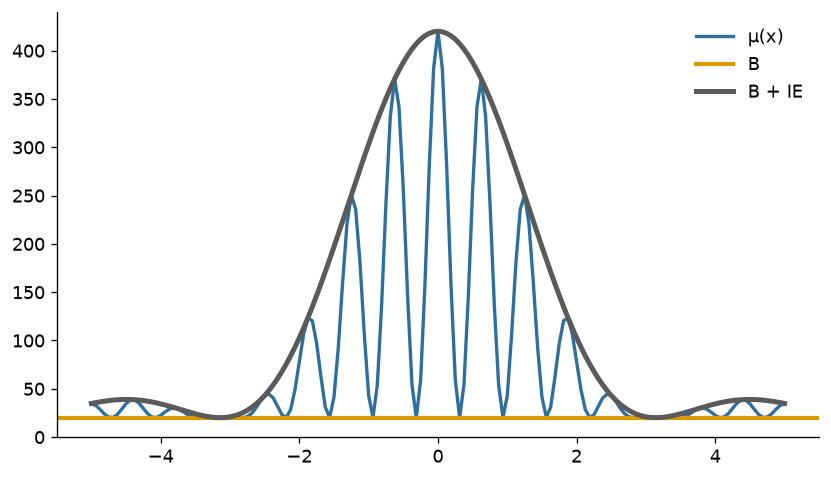

In [108]:
def mu(x):
    E = np.sinc(alfa*x/np.pi)**2
    C = np.cos(delta*x)**2
    return B + I*E*C
x = np.linspace(-5., 5., 161)
mu_x = mu(x)
is_finite = np.isfinite(mu_x).all()
is_positive = (mu_x >= 0).all()
is_even = (mu_x == mu(-x)).all()
is_compatibile = np.allclose( mu(0), B + I)

print("La funzione è finita: ", is_finite)
print("La funzione è positiva: ", is_positive)
print("La funzione è pari: ", is_even)
print("le funzioni sono compatibile: ", is_compatibile)
fig, ax = plt.subplots()
ax.plot(x, mu_x, color= AZZURRO, lw=2, label= "μ(x)")
ax.axhline(B, color = ORO, lw = 2.5, label = "B")
ax.plot(x, B + I*np.sinc(alfa*x/np.pi)**2, color = GRIGIO, lw = 3, label = "B + IE")
ax.legend()
plt.show()


Aumentando delta la distanza fra le frange aumenta, se diminuisce la distanza fra le frange diminuisce. Aumentando alfa la larghezza del massimo centrale diminuisce, al contrario, se diminuisce, la larghezza aumenta. 

## *Simulazione di un'acquisizione*

<>:11: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
<>:11: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
C:\Users\miche\AppData\Local\Temp\ipykernel_22880\310502147.py:11: SyntaxWarning: "\p" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\p"? A raw string is also an option.
  ax.errorbar(x, n, yerr=error, fmt="o", linestyle="none", color= ROSSO, markersize=4.5, capsize=3, elinewidth=1.1, label="$ n \pm \sqrt{{n}}$")


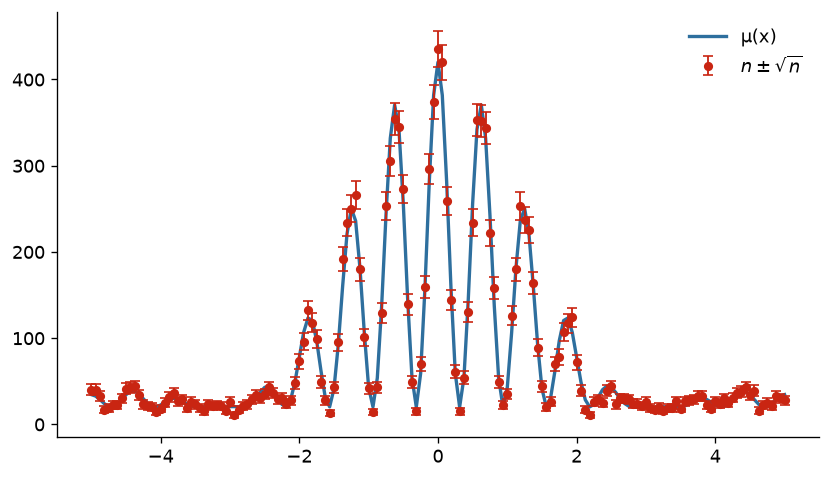

N_c - mu_c =  7.465175043459567
sqrt(mu_c) =  85.20836329283328
La differenza di N_c e mu_c è compatibile con una fluttuazione statistica:  True


In [109]:
rng = np.random.default_rng(42)
mask = np.abs(x) < 1.2
n = rng.poisson(mu_x)
N_c = np.sum(n[mask])
mu_c = np.sum(mu_x[mask])
error = np.sqrt(n)
error [n==0] = 1

fig, ax = plt.subplots()
ax.plot(x, mu_x, color= AZZURRO, lw=2, label= "μ(x)")
ax.errorbar(x, n, yerr=error, fmt="o", linestyle="none", color= ROSSO, markersize=4.5, capsize=3, elinewidth=1.1, label="$ n \pm \sqrt{{n}}$")
plt.legend()
plt.show()

print("N_c - mu_c = ", np.abs(N_c - mu_c))
print("sqrt(mu_c) = ", np.sqrt(mu_c))
compatibility = np.abs(N_c - mu_c) < np.sqrt(mu_c)
print("La differenza di N_c e mu_c è compatibile con una fluttuazione statistica: ", compatibility)


## *Distribuzione dello stimatore*

Numero di acquisizioni: 2000
Media simulata: 7263.023
Valore atteso μ_c: 7260.465
Deviazione standard (ddof=1): 85.441
Deviazione standard teorica √μ_c: 85.208
Errore sulla media: 1.911
Scarto relativo assoluto: 0.035%
85.44112337616993 85.20836329283328
1.0027316577192866


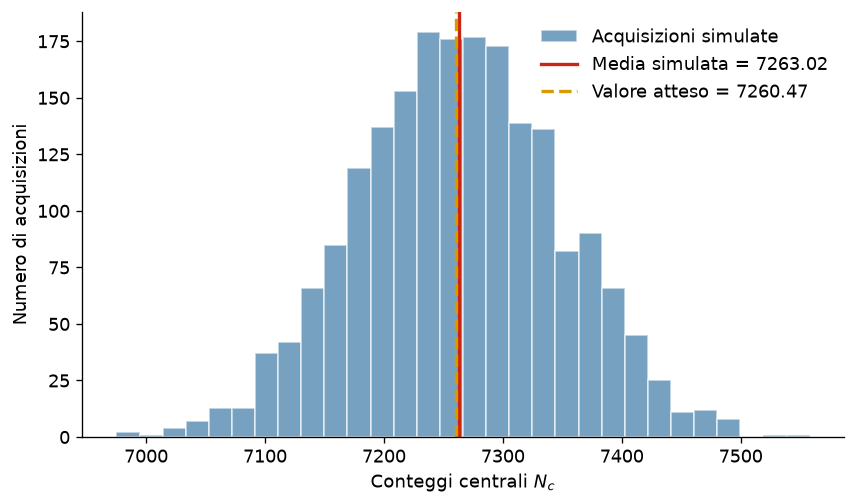

In [110]:
M = 2000

def esperimento():
    return rng.poisson(mu_x)

# Conserva tutti i conteggi: 2000 esperimenti × 161 posizioni
conteggi_mc = np.array([esperimento() for _ in range(M)])

# Totale centrale di ogni esperimento, usato dal grafico precedente
N_c_arr = conteggi_mc[:, mask].sum(axis=1)
mean = N_c_arr.mean()
standard_deviation = N_c_arr.std(ddof=1)
mean_error = standard_deviation / np.sqrt(M)
relative_discard = np.abs(mean - mu_c) / mu_c

print(f"Numero di acquisizioni: {M}")
print(f"Media simulata: {mean:.3f}")
print(f"Valore atteso μ_c: {mu_c:.3f}")
print(f"Deviazione standard (ddof=1): {standard_deviation:.3f}")
print(f"Deviazione standard teorica √μ_c: {np.sqrt(mu_c):.3f}")
print(f"Errore sulla media: {mean_error:.3f}")
print(f"Scarto relativo assoluto: {relative_discard:.3%}")

print(standard_deviation, np.sqrt(mu_c))
print(standard_deviation / np.sqrt(mu_c))
fig, ax = plt.subplots()

ax.hist(N_c_arr, bins=30, color=AZZURRO, alpha=0.65,
        edgecolor="white", label="Acquisizioni simulate")

ax.axvline(mean, color=ROSSO, linewidth=2,
           label=f"Media simulata = {mean:.2f}")

ax.axvline(mu_c, color=ORO, linewidth=2, linestyle="--",
           label=f"Valore atteso = {mu_c:.2f}")

ax.set_xlabel(r"Conteggi centrali $N_c$")
ax.set_ylabel("Numero di acquisizioni")
ax.legend()
plt.show()



L'incertezza sulla singola acquisizione è la deviazione standard. Aumentando M  l'incertezza sulla media diminuisce. 

# **Lab2**

### *Caricamento e controllo dei dati*

Dimensioni delle acquisizioni: (2000, 161)
Numero di medie: 161
Posizioni con incertezza nulla: []
Gli array hanno la stessa lunghezza? True
Gli array contengono tutti valori finiti? True
Le incertezze sono tutte positive? True
Le posizioni sono crescenti? True
Numero di punti: 161
Intervallo x: -5.0 5.0
Intervallo y: 19.873 420.076
Intervallo sigma_y: 0.09769886083626748 0.46810220234038374


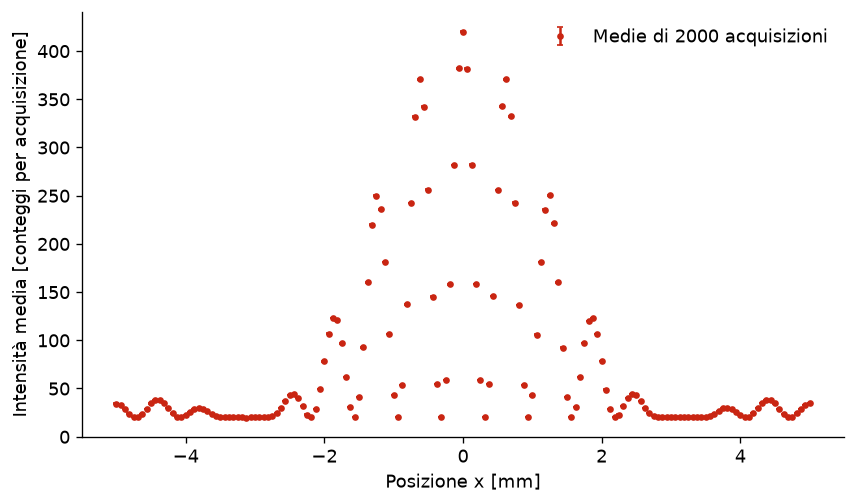

In [111]:
media_posizione = conteggi_mc.mean(axis=0)
std_posizione = conteggi_mc.std(axis=0, ddof=1)
incertezza_media = std_posizione / np.sqrt(M)

print("Dimensioni delle acquisizioni:", conteggi_mc.shape)
print("Numero di medie:", len(media_posizione))

incertezze_nulle = incertezza_media == 0
print("Posizioni con incertezza nulla:", x[incertezze_nulle])

np.savez(
    "acquisizioni_complete.npz",
    x=x,
    conteggi=conteggi_mc,
    media=media_posizione,
    incertezza_media=incertezza_media
)

dati_fit = np.column_stack((
    x,
    media_posizione,
    incertezza_media
))

np.savetxt(
    "dati_fit_interferenza.csv",
    dati_fit,
    delimiter=",",
    header="x,y,sigma_y",
    comments=""
)

dati = np.genfromtxt(
    "dati_fit_interferenza.csv",
    delimiter=",",
    names=True
)

x_fit = dati["x"]
y = dati["y"]
sigma_y = dati["sigma_y"]

control_length = len(x_fit) == len(y) == len(sigma_y)
control_finite = (
    np.isfinite(x_fit).all()
    and np.isfinite(y).all()
    and np.isfinite(sigma_y).all()
)
control_positive = (sigma_y >= 0).all()
control_order = (np.diff(x_fit) > 0).all()

print("Gli array hanno la stessa lunghezza?", control_length)
print("Gli array contengono tutti valori finiti?", control_finite)
print("Le incertezze sono tutte positive?", control_positive)
print("Le posizioni sono crescenti?", control_order)

print("Numero di punti:", len(x_fit))
print("Intervallo x:", x_fit.min(), x_fit.max())
print("Intervallo y:", y.min(), y.max())
print("Intervallo sigma_y:", sigma_y.min(), sigma_y.max())

fig, ax = plt.subplots()

ax.errorbar(
    x_fit, y,
    yerr=sigma_y,
    fmt="o",
    color=ROSSO,
    markersize=3,
    capsize=2,
    label="Medie di 2000 acquisizioni"
)

ax.set_xlabel("Posizione x [mm]")
ax.set_ylabel("Intensità media [conteggi per acquisizione]")
ax.legend()
plt.show()



## *Stime iniziali e bounds*

In [112]:
B_0 = np.median(y[np.abs(x_fit)>3])
I_0 = max(y) - B_0
print("La stima di B è: ", B_0)
print("La stima dell'ampiezza è: ", I_0)
lower = [0.0, 0.0, 0.10, 1.0] 
upper = [np.inf, np.inf, 3.0, 12.0]


La stima di B è:  23.8265
La stima dell'ampiezza è:  396.2495


## *fit pesato*

La stima di B è:  19.980921429677487  ±  0.01112263128629311
La stima di I è:  400.14105536588477  ±  0.11802334879888206
La stima di alfa è:  1.000121746546551  ±  0.00017799601771929688
La stima di delta è:  5.000016693478508  ±  0.0001485531824024603


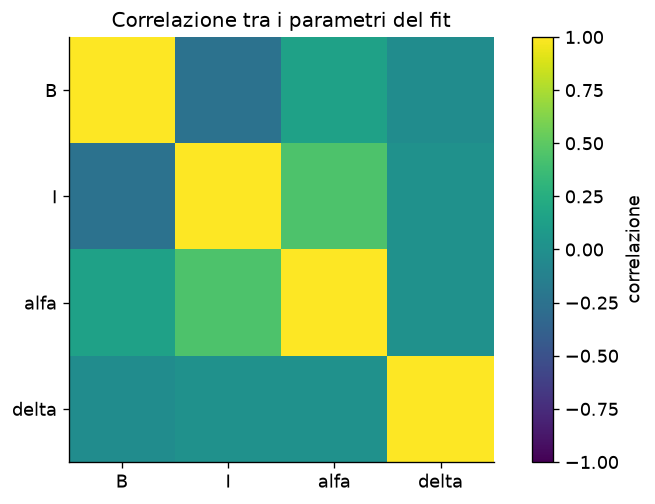

[[ 1.   -0.24  0.15 -0.02]
 [-0.24  1.    0.44  0.01]
 [ 0.15  0.44  1.    0.01]
 [-0.02  0.01  0.01  1.  ]]


In [113]:
def modello(x, B, I, alfa, delta):
    E = np.sinc(alfa*x/np.pi)**2
    C = np.cos(delta*x)**2
    return B + I*E*C
p0 = [B_0, I_0, 1.0, 5.0] 

popt, pcov = curve_fit( 
    modello, x, y, 
    p0=p0, 
    sigma=sigma_y, 
    absolute_sigma=True, 
    bounds=(lower, upper), 
    maxfev=100000 
)

sigma_popt = np.sqrt(np.diag(pcov))

print("La stima di B è: ", popt[0], " ± ", sigma_popt[0])
print("La stima di I è: ", popt[1], " ± ", sigma_popt[1])
print("La stima di alfa è: ", popt[2], " ± ", sigma_popt[2])
print("La stima di delta è: ", popt[3], " ± ", sigma_popt[3])

rho = pcov / np.sqrt(np.outer(sigma_popt, sigma_popt))
errors = np.sqrt(np.diag(pcov))
corr = pcov / np.outer(errors, errors)

plt.imshow(corr, vmin=-1, vmax=1)
plt.xticks(range(len(popt)), ["B", "I", "alfa", "delta"])
plt.yticks(range(len(popt)), ["B", "I", "alfa", "delta"])
plt.colorbar(label="correlazione")
plt.title("Correlazione tra i parametri del fit")
plt.show()

print(np.round(corr, 2))

## *diagnostica del fit*

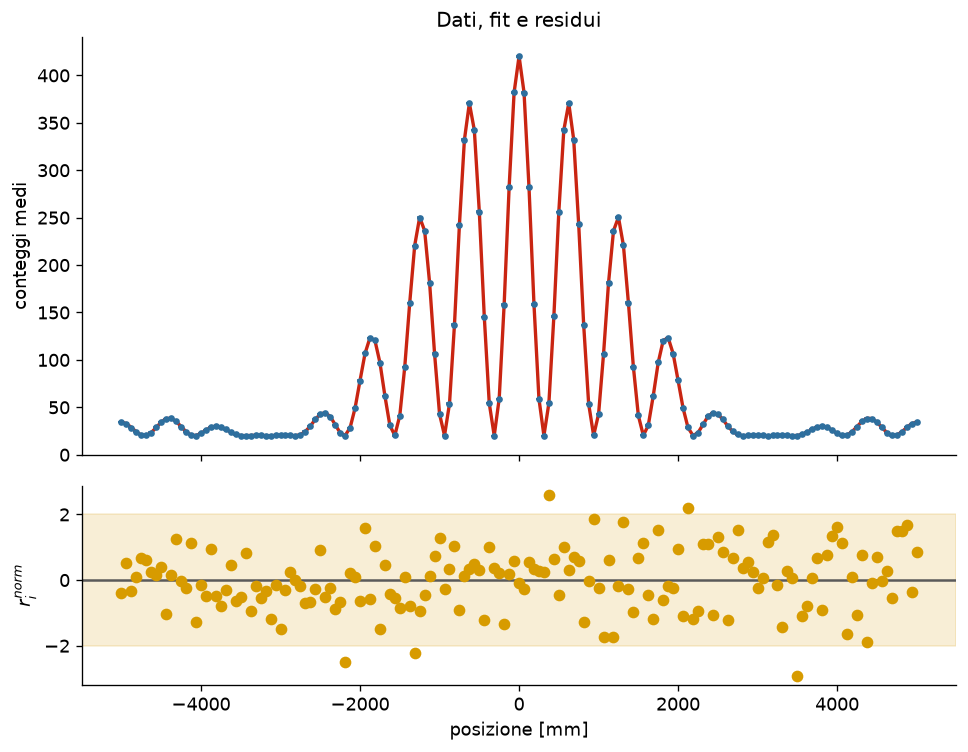

In [114]:
residuals = y - modello(x_fit, *popt)
pulls = residuals / sigma_y
chi2_ = np.sum(pulls**2)
degrees_of_freedom = len(y) - len(popt)
chi2_per_dof = chi2_ / degrees_of_freedom
from scipy.stats import chi2 
p_value = chi2.sf(chi2_, degrees_of_freedom)

fig, ax = plt.subplots(2, 1, figsize=(8.2, 6.4), sharex=True,
                       gridspec_kw={"height_ratios": [2.1, 1]})
ax[0].errorbar(x_fit*1e3, y, yerr=sigma_y, fmt="o", color=AZZURRO, markersize=3, capsize=2, label="Dati")
ax[0].plot(x_fit*1e3, modello(x_fit, *popt), color=ROSSO, lw=2)
ax[0].set(ylabel="conteggi medi", title="Dati, fit e residui")
ax[1].axhline(0, color=GRIGIO, lw=1.5)
ax[1].axhspan(-2, 2, color=ORO, alpha=0.16)
ax[1].plot(x_fit*1e3, pulls, "o", color=ORO)
ax[1].set(xlabel="posizione [mm]", ylabel=r"$r_i^{norm}$")
fig.tight_layout()
plt.show()

## **lab3**


In [115]:
alpha_hat = 0.910
delta_hat = 5.180
u_alpha = 0.018
u_delta = 0.045
rho_alpha_delta = -0.65
k = 1.
sigma_k = 0.015
sx = 1
sigma_sx = 0.02
a_0 = alpha_hat* (k*sx)
d_0 = delta_hat* (k*sx)
q_0 = delta_hat/alpha_hat




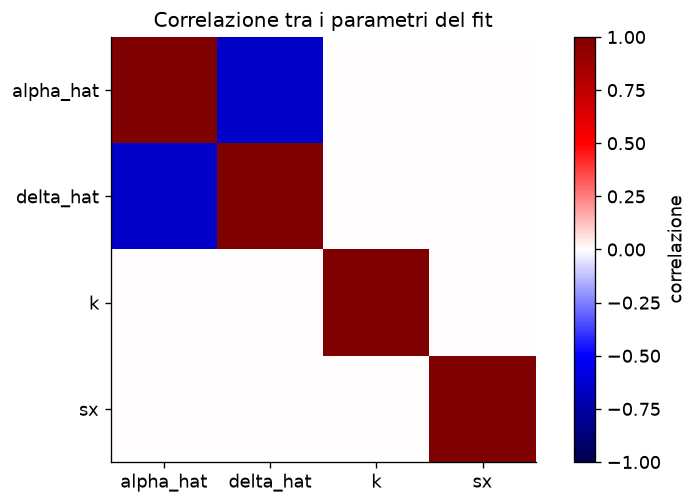

La matrice di covarianza è simmetrica? True
La matrice di covarianza è diagonale? True
La matrice di covarianza è definita positiva? True
La correlazione tra alpha_hat e delta_hat è: -0.65
Gli autovalori della matrice di covarianza sono: [0.00017422 0.000225   0.0004     0.00217478]


In [116]:
z = np.array([alpha_hat, delta_hat, k, sx])
C_z = np.array([
    [u_alpha**2, rho_alpha_delta*u_alpha*u_delta, 0, 0],
    [rho_alpha_delta*u_alpha*u_delta, u_delta**2, 0, 0],
    [0, 0, sigma_k**2, 0],
    [0, 0, 0, sigma_sx**2]])

is_simmetric = np.allclose(C_z, C_z.T)
is_diagonal = np.all(np.diag(C_z)>0)
autovalori = np.linalg.eigvalsh(C_z)
is_positive_definite = np.all(autovalori>0)
corr_matrix = C_z / np.sqrt(np.outer(np.diag(C_z), np.diag(C_z)))
corr_alpha_delta = corr_matrix[0, 1]

plt.imshow(corr_matrix, vmin=-1, vmax=1, cmap="seismic")
plt.xticks(range(len(z)), ["alpha_hat", "delta_hat", "k", "sx"])
plt.yticks(range(len(z)), ["alpha_hat", "delta_hat", "k", "sx"])
plt.colorbar(label="correlazione")
plt.title("Correlazione tra i parametri del fit")
plt.show()

print("La matrice di covarianza è simmetrica?", is_simmetric)
print("La matrice di covarianza è diagonale?", is_diagonal)
print("La matrice di covarianza è definita positiva?", is_positive_definite)
print("La correlazione tra alpha_hat e delta_hat è:", corr_alpha_delta)
print("Gli autovalori della matrice di covarianza sono:", autovalori)



### *attività 2*

In [117]:
g_z = np.array([a_0, d_0, q_0])
J = np.array([
    [1/(k*sx), 0, -alpha_hat/(k*k*sx), -alpha_hat/(k*sx*sx)],
    [0, 1/(k*sx), -delta_hat/(k*k*sx), -delta_hat/(k*sx*sx)],
    [-delta_hat/alpha_hat**2, 1/alpha_hat, 0, 0]
])
C_g = J @ C_z @ J.T
marginal_errors = np.sqrt(np.diag(C_g))
corr_matrix_g = C_g / np.sqrt(np.outer(np.diag(C_g), np.diag(C_g)))
u_q = marginal_errors[2]
check_q_1 = f"{(u_q/q_0)**2:.5f}"
check_q_2 = f"{(u_delta/delta_hat)**2 + (u_alpha/alpha_hat)**2 - 2*rho_alpha_delta * (u_alpha/alpha_hat) * (u_delta/delta_hat):.5f}"
is_verified = (check_q_1 == check_q_2)
print("Verifica della propagazione dell'incertezza di q:", is_verified)


Verifica della propagazione dell'incertezza di q: True


### *attività 3*

0.9100321596809575 0.01802358352046731 0.9100181261893707 0.8921046783959867 0.9280669873304673
5.179881599596114 0.04497987737389264 5.179931681414612 5.135121412972983 5.224770193465137
5.694848034560064 0.1498472022883163 5.692137611995676 5.54522977665195 5.8438150773572675


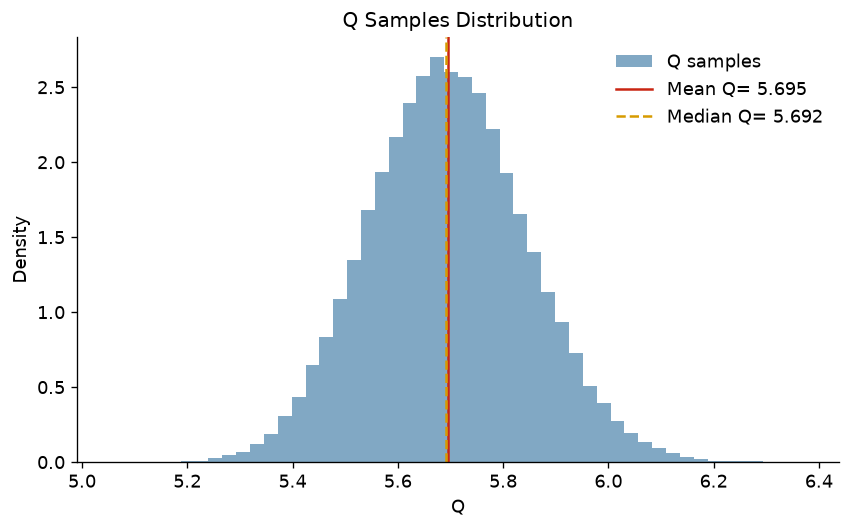

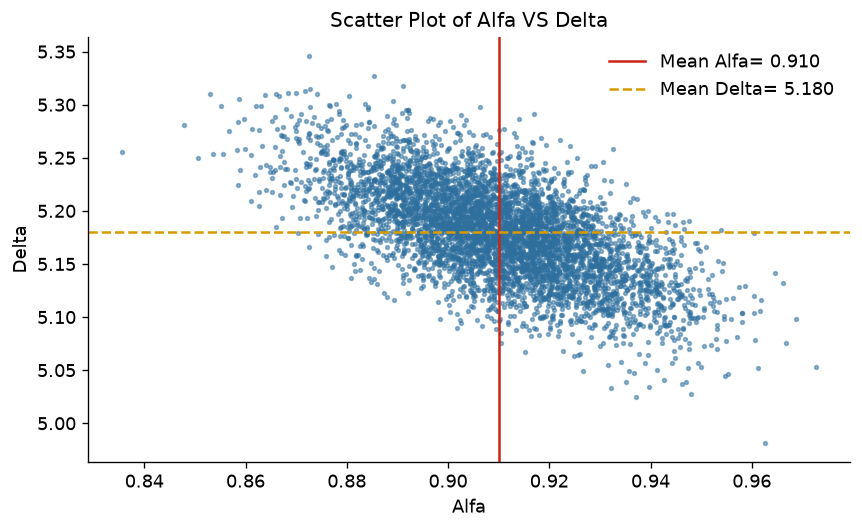

valori nominali:  alfa: 0.91 delta: 5.18 q: 5.692307692307692
errori marginali:  [0.0290097  0.13709577 0.14953685]
media campionaria:  alfa: 0.9100321596809575 delta: 5.179881599596114 q: 5.694848034560064
deviazione standard campionaria:  alfa: 0.01802358352046731 delta: 0.04497987737389264 q: 0.1498472022883163
intervallo 16-84% campionaria:  alfa: 0.8921046783959867 0.9280669873304673 delta: 5.135121412972983 5.224770193465137 q: 5.54522977665195 5.8438150773572675


In [118]:
M = 100000
rng = np.random.default_rng(20261003) 
campioni = rng.multivariate_normal( 
    mean=z, 
    cov=C_z, 
    size=M 
)

alfa_samples = campioni[:, 0]
delta_samples = campioni[:, 1]
k_samples = campioni[:, 2]
sx_samples = campioni[:, 3]
a_samples = alfa_samples * (k_samples * sx_samples)
d_samples = delta_samples * (k_samples * sx_samples)
q_samples = delta_samples / alfa_samples
accepted = (a_samples > 0) & (d_samples > 0) & (q_samples > 0)

alfa_mean = np.mean(alfa_samples)
alfa_std = np.std(alfa_samples, ddof=1)
alfa_median = np.median(alfa_samples)
alfa_16 = np.percentile(alfa_samples, 16)
alfa_84 = np.percentile(alfa_samples, 84)
print(alfa_mean, alfa_std, alfa_median, alfa_16, alfa_84)

delta_mean = np.mean(delta_samples)
delta_std = np.std(delta_samples, ddof=1)
delta_median = np.median(delta_samples)
delta_16 = np.percentile(delta_samples, 16)
delta_84 = np.percentile(delta_samples, 84)
print(delta_mean, delta_std, delta_median, delta_16, delta_84)
q_mean = np.mean(q_samples)
q_std = np.std(q_samples, ddof=1)
q_median = np.median(q_samples)
q_16 = np.percentile(q_samples, 16)
q_84 = np.percentile(q_samples, 84)
print(q_mean, q_std, q_median, q_16, q_84)

plt.figure()
plt.hist(q_samples, bins=50, density=True, alpha=0.6, color=AZZURRO, label= "Q samples")
plt.axvline(q_mean, color=ROSSO, linestyle="-", label=f"Mean Q= {q_mean:.3f}")
plt.axvline(q_median, color=ORO, linestyle="--", label=f"Median Q= {q_median:.3f}")
plt.xlabel("Q")
plt.ylabel("Density")
plt.title("Q Samples Distribution")
plt.legend()
plt.show()

n= 5000
plt.figure()
plt.scatter(alfa_samples[:n], delta_samples[:n], s=5, alpha=0.5, color=AZZURRO)
plt.xlabel("Alfa")
plt.ylabel("Delta")
plt.title("Scatter Plot of Alfa VS Delta")
plt.axvline(alfa_mean, color=ROSSO, linestyle="-", label=f"Mean Alfa= {alfa_mean:.3f}")
plt.axhline(delta_mean, color=ORO, linestyle="--", label=f"Mean Delta= {delta_mean:.3f}")
plt.legend()
plt.show()

print("valori nominali: ", "alfa:", a_0, "delta:", d_0, "q:", q_0)
print("errori marginali: ", marginal_errors)
print("media campionaria: ", "alfa:", np.mean(alfa_samples), "delta:", np.mean(delta_samples), "q:", np.mean(q_samples))
print("deviazione standard campionaria: ", "alfa:", np.std(alfa_samples, ddof=1), "delta:", np.std(delta_samples, ddof=1), "q:", np.std(q_samples, ddof=1))
print("intervallo 16-84% campionaria: ", "alfa:", alfa_16, alfa_84, "delta:", delta_16, delta_84, "q:", q_16, q_84)

## *attività 4*


In [119]:
new_rho = 0
new_C_z = np.array([
    [u_alpha**2, new_rho*u_alpha*u_delta, 0, 0],
    [new_rho*u_alpha*u_delta, u_delta**2, 0, 0],
    [0, 0, sigma_k**2, 0],
    [0, 0, 0, sigma_sx**2]])
corr_matrix = new_C_z / np.sqrt(np.outer(np.diag(new_C_z), np.diag(new_C_z)))
new_corr_alpha_delta = corr_matrix[0, 1]
new_C_g = J @ new_C_z @ J.T

new_marginal_errors = np.sqrt(np.diag(new_C_g))
new_corr_matrix_g = new_C_g / np.sqrt(np.outer(np.diag(new_C_g), np.diag(new_C_g)))

print("Nuova matrice di covarianza C_z con rho=0:\n", new_C_z)
print("Nuova matrice di correlazione C_z con rho=0:\n", corr_matrix)
print("Nuova correlazione tra alfa e delta con rho=0:\n", new_corr_alpha_delta)
print("Nuove errori marginali:\n", new_marginal_errors)
print("Nuova matrice di correlazione C_g con rho=0:\n", new_corr_matrix_g)


Nuova matrice di covarianza C_z con rho=0:
 [[0.000324 0.       0.       0.      ]
 [0.       0.002025 0.       0.      ]
 [0.       0.       0.000225 0.      ]
 [0.       0.       0.       0.0004  ]]
Nuova matrice di correlazione C_z con rho=0:
 [[1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [0. 0. 0. 1.]]
Nuova correlazione tra alfa e delta con rho=0:
 0.0
Nuove errori marginali:
 [0.0290097  0.13709577 0.12297566]
Nuova matrice di correlazione C_g con rho=0:
 [[ 1.          0.74077093 -0.56810634]
 [ 0.74077093  1.          0.13198982]
 [-0.56810634  0.13198982  1.        ]]


0.9099797290471432 0.018005686957883377 0.9099789790118633 0.8921442211602474 0.9278816929235612
5.179881618348026 0.044984460794280305 5.179945621679684 5.135150574815832 5.224627620472203
5.694535089274168 0.12314830992472585 5.692427810113608 5.571815900911623 5.817017932987546


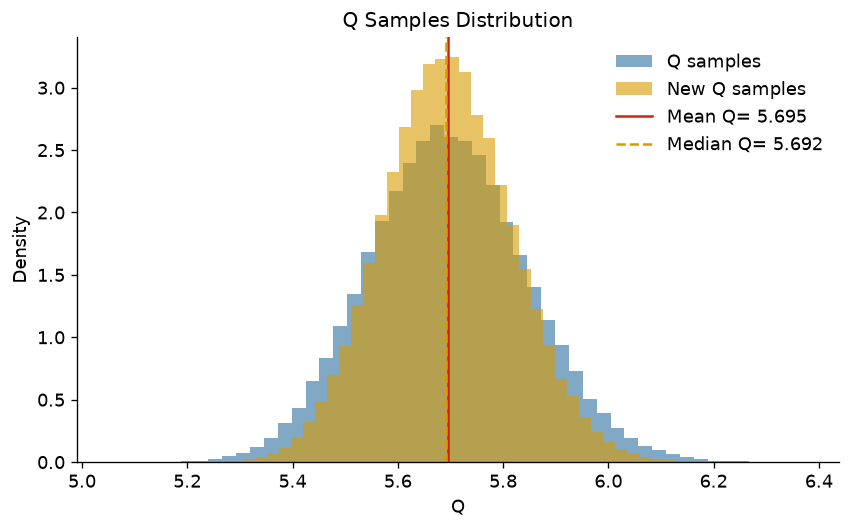

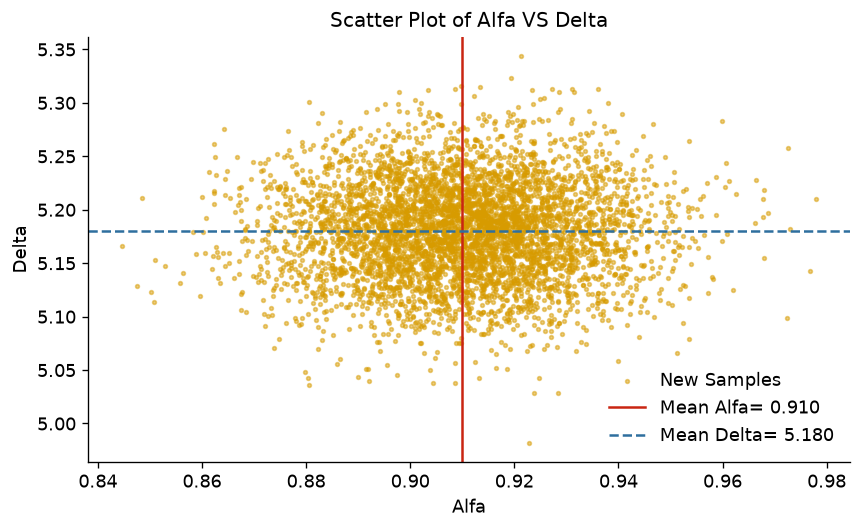

valori nominali:  alfa: 0.91 delta: 5.18 q: 5.692307692307692
errori marginali:  [0.0290097  0.13709577 0.12297566]
media campionaria:  alfa: 0.9099797290471432 delta: 5.179881618348026 q: 5.694535089274168
deviazione standard campionaria:  alfa: 0.018005686957883377 delta: 0.044984460794280305 q: 0.12314830992472585
intervallo 16-84% campionaria:  alfa: 0.8921442211602474 0.9278816929235612 delta: 5.135150574815832 5.224627620472203 q: 5.571815900911623 5.817017932987546


In [126]:
M= 100000
rng = np.random.default_rng(20261003)
campioni = rng.multivariate_normal(
    mean=z,
    cov=new_C_z,
    size=M
)
new_alfa_samples = campioni[:, 0]
new_delta_samples = campioni[:, 1]
new_k_samples = campioni[:, 2]
new_sx_samples = campioni[:, 3]
new_a_samples = new_alfa_samples * (new_k_samples * new_sx_samples)
new_d_samples = new_delta_samples * (new_k_samples * new_sx_samples)
new_q_samples = new_delta_samples / new_alfa_samples
accepted = (new_a_samples > 0) & (new_d_samples > 0) & (new_q_samples > 0)

new_alfa_mean = np.mean(new_alfa_samples)
new_alfa_std = np.std(new_alfa_samples, ddof=1)
new_alfa_median = np.median(new_alfa_samples)
new_alfa_16 = np.percentile(new_alfa_samples, 16)
new_alfa_84 = np.percentile(new_alfa_samples, 84)
print(new_alfa_mean, new_alfa_std, new_alfa_median, new_alfa_16, new_alfa_84)

new_delta_mean = np.mean(new_delta_samples)
new_delta_std = np.std(new_delta_samples, ddof=1)
new_delta_median = np.median(new_delta_samples)
new_delta_16 = np.percentile(new_delta_samples, 16)
new_delta_84 = np.percentile(new_delta_samples, 84)
print(new_delta_mean, new_delta_std, new_delta_median, new_delta_16, new_delta_84)
new_q_mean = np.mean(new_q_samples)
new_q_std = np.std(new_q_samples, ddof=1)
new_q_median = np.median(new_q_samples)
new_q_16 = np.percentile(new_q_samples, 16)
new_q_84 = np.percentile(new_q_samples, 84)
print(new_q_mean, new_q_std, new_q_median, new_q_16, new_q_84)

plt.figure()
plt.hist(q_samples, bins=50, density=True, alpha=0.6, color=AZZURRO, label= "Q samples")
plt.hist(new_q_samples, bins=50, density=True, alpha=0.6, color=ORO, label= "New Q samples")
plt.axvline(new_q_mean, color=ROSSO, linestyle="-", label=f"Mean Q= {new_q_mean:.3f}")
plt.axvline(new_q_median, color=ORO, linestyle="--", label=f"Median Q= {new_q_median:.3f}")
plt.xlabel("Q")
plt.ylabel("Density")
plt.title("Q Samples Distribution")
plt.legend()
plt.show()

n= 5000
plt.figure()
plt.scatter(new_alfa_samples[:n], new_delta_samples[:n], s=5, alpha=0.5, color=ORO, label="New Samples")
plt.xlabel("Alfa")
plt.ylabel("Delta")
plt.title("Scatter Plot of Alfa VS Delta")
plt.axvline(new_alfa_mean, color=ROSSO, linestyle="-", label=f"Mean Alfa= {new_alfa_mean:.3f}")
plt.axhline(new_delta_mean, color=AZZURRO, linestyle="--", label=f"Mean Delta= {new_delta_mean:.3f}")
plt.legend()
plt.show()

print("valori nominali: ", "alfa:", a_0, "delta:", d_0, "q:", q_0)
print("errori marginali: ", new_marginal_errors)
print("media campionaria: ", "alfa:", np.mean(new_alfa_samples), "delta:", np.mean(new_delta_samples), "q:", np.mean(new_q_samples))
print("deviazione standard campionaria: ", "alfa:", np.std(new_alfa_samples, ddof=1), "delta:", np.std(new_delta_samples, ddof=1), "q:", np.std(new_q_samples, ddof=1))
print("intervallo 16-84% campionaria: ", "alfa:", new_alfa_16, new_alfa_84, "delta:", new_delta_16, new_delta_84, "q:", new_q_16, new_q_84)

